# Gold Price Forecasting: Walk-Forward Validation with Strictly Lagged Features

**Contributors:** Sathwika Garlapati · Shehan Makani · Prarthna Rana

---

## Project Summary

This notebook implements a **genuine next-day forecasting pipeline** for gold prices using walk-forward cross-validation with features built only from data available at the forecast origin. Key design decisions:

| Design Choice | This Notebook |
|---|---|
| **Prediction target** | Next trading day's closing price (t+1) |
| **Feature timing** | Only data known at the close of day t (forecast origin), used to predict day t+1 |
| **Evaluation** | Walk-forward cross-validation with nested hyperparameter tuning |
| **Baselines** | Persistence (naïve) + 7-day moving-average baseline included |
| **Dataset** | MCX India gold spot price, INR/10g, 2014-01-01 → 2026-01-02 (3,104 rows) |
| **Models** | Ridge Regression, XGBoost, SVR, Random Forest |

### Data Source
The dataset is the **Kaggle "Daily Gold Price" dataset** (originally labelled 2015–2021 by Kaggle but the file contains data from 2014-01-01 through 2026-01-02 with 3,104 observations).  
Prices are denominated in **Indian Rupees (INR) per 10 grams** — the standard MCX (Multi Commodity Exchange) format — which is why values appear in the 25,000–140,000 range rather than the USD/oz scale used on COMEX.


## 0. Imports & Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV

from xgboost import XGBRegressor
from statsmodels.tsa.stattools import adfuller

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (13, 4)
sns.set_theme(style="whitegrid")

# ── Walk-Forward Configuration ────────────────────────────────
INITIAL_TRAIN_DAYS = 500   # ~2 years of history before first forecast
STEP_SIZE          = 21    # advance by ~1 trading month per fold
FORECAST_HORIZON   = 1     # strictly next-day (t+1) prediction

print("Configuration loaded.")
print(f"  Initial training window : {INITIAL_TRAIN_DAYS} days")
print(f"  Step size               : {STEP_SIZE} days")
print(f"  Forecast horizon        : {FORECAST_HORIZON} day(s) ahead")


Configuration loaded.
  Initial training window : 500 days
  Step size               : 21 days
  Forecast horizon        : 1 day(s) ahead


## 1. Data Loading & Description

### Dataset Facts
- **File:** `Gold Price.csv` (MCX India gold spot price)
- **Shape:** 3,104 rows × 7 columns (Date, Price, Open, High, Low, Volume, Chg%)
- **Date range:** 2014-01-01 → 2026-01-02
- **Price units:** INR per 10 grams (MCX convention; ~₹29,000–₹1,38,000 over this window)
- **Target variable:** `Price` (daily closing price in INR/10g)

> **Note on pricing scale:** Values in the 25,000–140,000 range are correct for MCX gold.  
> 1 troy oz ≈ 31.1 g, so an MCX price of ₹100,000/10g ≈ ₹310,000/oz ≈ $3,700/oz at 84 INR/USD — consistent with global gold prices.


In [2]:
import os

# ── Environment-aware data loading ────────────────────────────
# Works on Kaggle, Google Colab, and local without any manual uploads.
if os.path.exists("/kaggle/input/daily-gold-price-20152021-time-series/Gold Price.csv"):
    # Kaggle: dataset is auto-mounted
    DATA_PATH = "/kaggle/input/daily-gold-price-20152021-time-series/Gold Price.csv"
elif os.path.exists("Gold Price.csv"):
    # Local: file in working directory
    DATA_PATH = "Gold Price.csv"
else:
    # Colab or any other environment: read directly from GitHub
    DATA_PATH = "https://raw.githubusercontent.com/shehanmakani/gold-price-prediction/main/Gold%20Price.csv"

print(f"Loading data from: {DATA_PATH}")

def clean_numeric(series):
    """Strip commas, percent signs, K/M suffixes and coerce to float."""
    return pd.to_numeric(
        series.astype(str)
            .str.replace(",", "", regex=False)
            .str.replace("%", "", regex=False)
            .str.replace("K", "e3", regex=False)
            .str.replace("M", "e6", regex=False),
        errors="coerce"
    )

# Load & sort
df_raw = pd.read_csv(DATA_PATH)
df_raw["Date"] = pd.to_datetime(df_raw["Date"], errors="coerce")
df_raw = df_raw.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

for col in ["Price", "Open", "High", "Low", "Volume", "Chg%"]:
    df_raw[col] = clean_numeric(df_raw[col])

print("=== Dataset Overview ===")
print(f"Shape         : {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print(f"Date range    : {df_raw['Date'].min().date()}  →  {df_raw['Date'].max().date()}")
print(f"Price range   : ₹{df_raw['Price'].min():,.0f}  –  ₹{df_raw['Price'].max():,.0f}  (INR/10g)")
print(f"Missing values:\n{df_raw.isnull().sum()}")
display(df_raw.head(5))
display(df_raw.tail(5))
display(df_raw.describe())

Loading data from: Gold Price.csv
=== Dataset Overview ===
Shape         : 3104 rows × 7 columns
Date range    : 2014-01-01  →  2026-01-02
Price range   : ₹24,545  –  ₹137,789  (INR/10g)
Missing values:
Date      0
Price     0
Open      0
High      0
Low       0
Volume    0
Chg%      0
dtype: int64


,Date,Price,Open,High,Low,Volume,Chg%
0,2014-01-01,29542,29435,29598,29340,2930,0.25
1,2014-01-02,29975,29678,30050,29678,3140,1.47
2,2014-01-03,29727,30031,30125,29539,3050,-0.83
3,2014-01-04,29279,29279,29279,29279,0,-1.51
4,2014-01-06,29119,29300,29395,29051,24380,-0.55


,Date,Price,Open,High,Low,Volume,Chg%
3099,2025-12-29,132595,137628,138269,131695,90640,-3.77
3100,2025-12-30,133974,133185,134880,132853,36733,1.04
3101,2025-12-31,135454,136526,136527,134866,59050,1.10
3102,2026-01-01,135771,135687,135850,135001,14622,0.23
3103,2026-01-02,135793,136143,137037,135525,51877,0.02


,Date,Price,Open,High,Low,Volume,Chg%
count,3104,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000
mean,2019-12-23 20:22:53.195876,46263.721972,46250.184278,46515.665271,45997.234214,14855.159472,0.052957
min,2014-01-01 00:00:00,24545.000000,24583.000000,24635.000000,24470.000000,0.000000,-5.980000
25%,2016-12-13 18:00:00,29358.750000,29331.500000,29462.750000,29214.000000,6780.000000,-0.370000
50%,2019-12-23 12:00:00,38832.500000,38902.500000,39083.000000,38626.500000,11520.000000,0.060000
75%,2022-12-27 06:00:00,54970.250000,54900.000000,55211.250000,54730.500000,18602.500000,0.480000
max,2026-01-02 00:00:00,137789.000000,137628.000000,138300.000000,136300.000000,149474.000000,5.300000
std,NaN,22230.385519,22191.261855,22364.944669,22053.596236,14197.123722,0.854364


## 2. Feature Engineering — Information Available at the Forecast Origin

### Design Principle — No Look-Ahead
The prediction task is: **given all information available at the *close* of day t, predict the closing price on day t+1.**

Features use data up to and including day t's close (the forecast origin). The target is `Price.shift(-1)`, so nothing from day t+1 is ever used as an input.

> **Changelog (fix):** earlier versions applied an extra `.shift(1)` on top of the one-day-ahead target, so the newest information the model saw was *yesterday's* close — it was effectively forecasting two days ahead. That extra shift has been removed. `Lag_k` now means the close *k−1* trading days before the origin, so `Lag_1` is today's close.

### Final Feature Set (19 features)

| Feature Group | Features | Data used |
|---|---|---|
| Price lags | Lag_1, Lag_5, Lag_10, Lag_21, Lag_63 | close on day t, t−4, t−9, t−20, t−62 |
| Moving averages | MA_7, MA_21, MA_63 | windows ending on day t |
| Rolling volatility | Std_7, Std_21 | windows ending on day t |
| Momentum / Rate-of-change | ROC_5, ROC_21 | ending on day t |
| Range volatility | HL_Spread (High−Low of day t) | day t |
| Log return | Log_Return (day t's return) | day t |
| Calendar | DayOfWeek, Month | day t |
| Trend signals | MA7_vs_MA21, MA21_vs_MA63 | ratios of the above |
| Z-score | ZScore_21 | day t vs 21-day window |


In [3]:
df = df_raw.copy()

# ── Lag features ─────────────────────────────────────────────
# Row t holds what is known at the close of day t; the target (below) is day t+1.
# Lag_k = close k-1 trading days before the origin, so Lag_1 is today's close.
for i in [1, 5, 10, 21, 63]:
    df[f"Lag_{i}"] = df["Price"].shift(i - 1)

# ── Rolling statistics (windows end on day t — no extra shift) ─
for window in [7, 21, 63]:
    df[f"MA_{window}"]  = df["Price"].rolling(window).mean()
    df[f"Std_{window}"] = df["Price"].rolling(window).std()

# ── Momentum ─────────────────────────────────────────────────
df["ROC_5"]  = df["Price"].pct_change(5) * 100
df["ROC_21"] = df["Price"].pct_change(21) * 100

# ── Day t's High-Low range (known at day t's close) ──────────
df["HL_Spread"] = df["High"] - df["Low"]

# ── Day t's log return ───────────────────────────────────────
df["Log_Return"] = np.log(df["Price"] / df["Price"].shift(1))

# ── Calendar ─────────────────────────────────────────────────
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["Month"]     = df["Date"].dt.month

# ── Trend-strength ratios ─────────────────────────────────────
df["MA7_vs_MA21"]  = (df["MA_7"]  / df["MA_21"]  - 1) * 100
df["MA21_vs_MA63"] = (df["MA_21"] / df["MA_63"] - 1) * 100

# ── Z-score of price relative to 21-day mean ─────────────────
df["ZScore_21"] = (df["Price"] - df["MA_21"]) / df["Std_21"]

# ── TARGET: next-day close (shift -1 so we predict t+1) ──────
df["Target"] = df["Price"].shift(-1)

# Final feature list
FEATURE_COLS = [
    "Lag_1", "Lag_5", "Lag_10", "Lag_21", "Lag_63",
    "MA_7", "MA_21", "MA_63",
    "Std_7", "Std_21",
    "ROC_5", "ROC_21",
    "HL_Spread", "Log_Return",
    "DayOfWeek", "Month",
    "MA7_vs_MA21", "MA21_vs_MA63",
    "ZScore_21"
]

TARGET_COL = "Target"

# Drop rows with NaN in features or target
df_model = df.dropna(subset=FEATURE_COLS + [TARGET_COL]).reset_index(drop=True)

print(f"Model-ready dataset: {df_model.shape[0]} rows")
print(f"Date range: {df_model['Date'].min().date()} → {df_model['Date'].max().date()}")
print(f"Features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"\nTarget column: '{TARGET_COL}' — next-day closing price (INR/10g)")
print("\nLeakage check: features use data up to the close of day t; target is day t+1 (Price.shift(-1)).")


Model-ready dataset: 3041 rows
Date range: 2014-03-27 → 2026-01-01
Features (19): ['Lag_1', 'Lag_5', 'Lag_10', 'Lag_21', 'Lag_63', 'MA_7', 'MA_21', 'MA_63', 'Std_7', 'Std_21', 'ROC_5', 'ROC_21', 'HL_Spread', 'Log_Return', 'DayOfWeek', 'Month', 'MA7_vs_MA21', 'MA21_vs_MA63', 'ZScore_21']

Target column: 'Target' — next-day closing price (INR/10g)

Leakage check: features use data up to the close of day t; target is day t+1 (Price.shift(-1)).


## 3. Stationarity Analysis (ADF Test)

Series                           ADF stat    p-value
-------------------------------------------------------
Raw Close (INR/10g)                6.0339     1.0000
Log Returns                      -55.9630     0.0000

Interpretation:
  Raw price   → p=1.0000 (NON-STATIONARY ✗)
  Log returns → p=0.000000 (STATIONARY ✓)


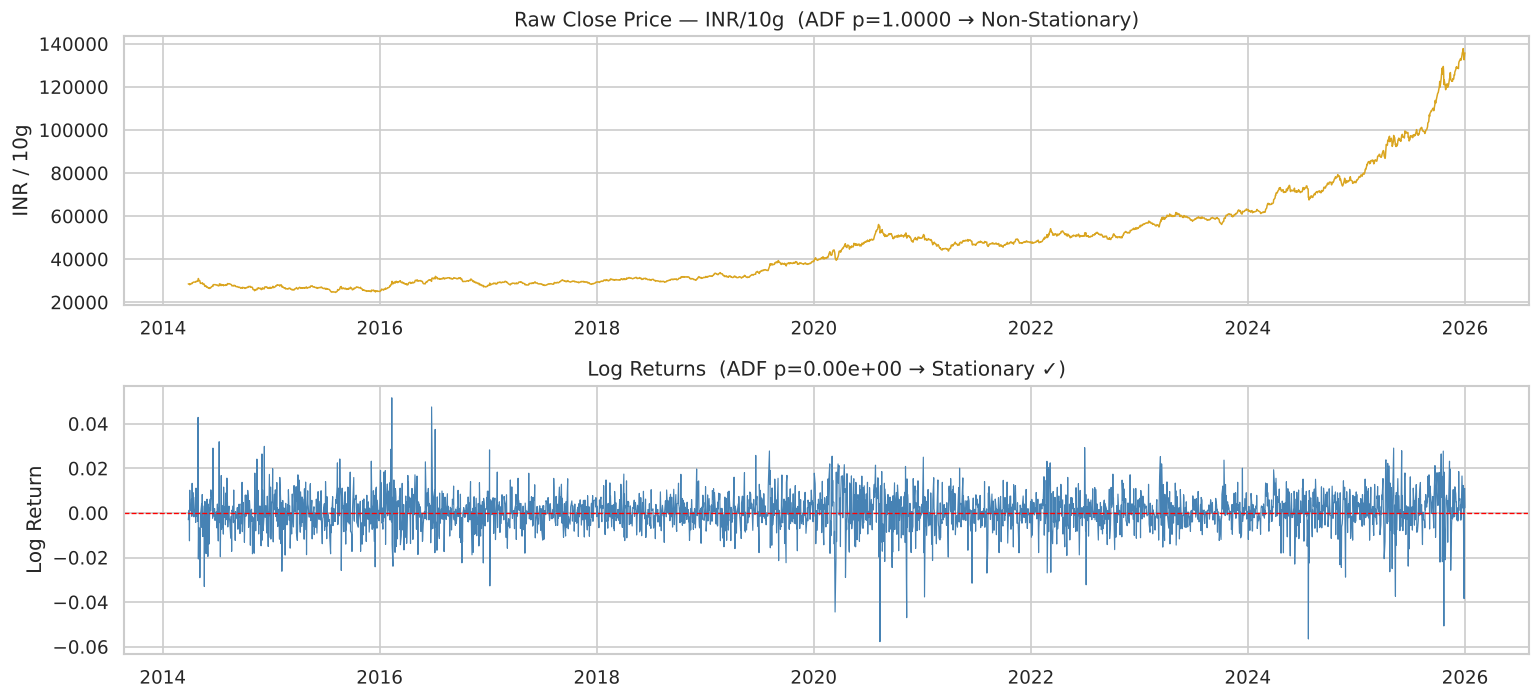

In [4]:
from statsmodels.tsa.stattools import adfuller

log_ret = np.log(df_model["Price"] / df_model["Price"].shift(1)).dropna()
adf_price   = adfuller(df_model["Price"],  autolag="AIC")
adf_returns = adfuller(log_ret, autolag="AIC")

print("=" * 55)
print(f"{'Series':<30} {'ADF stat':>10} {'p-value':>10}")
print("-" * 55)
print(f"{'Raw Close (INR/10g)':<30} {adf_price[0]:>10.4f} {adf_price[1]:>10.4f}")
print(f"{'Log Returns':<30} {adf_returns[0]:>10.4f} {adf_returns[1]:>10.4f}")
print("=" * 55)
print(f"\nInterpretation:")
print(f"  Raw price   → p={adf_price[1]:.4f} {'(NON-STATIONARY ✗)' if adf_price[1] > 0.05 else '(stationary ✓)'}")
print(f"  Log returns → p={adf_returns[1]:.6f} {'(STATIONARY ✓)'  if adf_returns[1] < 0.05 else '(non-stationary ✗)'}")

fig, axes = plt.subplots(2, 1, figsize=(13, 6))
axes[0].plot(df_model["Date"], df_model["Price"], lw=0.9, color="goldenrod")
axes[0].set_title(f"Raw Close Price — INR/10g  (ADF p={adf_price[1]:.4f} → Non-Stationary)", fontsize=12)
axes[0].set_ylabel("INR / 10g")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

axes[1].plot(df_model["Date"].iloc[1:], log_ret.values, lw=0.7, color="steelblue")
axes[1].axhline(0, color="red", lw=0.8, ls="--")
axes[1].set_title(f"Log Returns  (ADF p={adf_returns[1]:.2e} → Stationary ✓)", fontsize=12)
axes[1].set_ylabel("Log Return")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig("stationarity_analysis.png", bbox_inches="tight")
plt.show()


## 4. Baseline Models

Before evaluating ML models we establish two simple baselines that any useful model must beat. The table here covers every row; Section 5 re-scores both baselines on the exact walk-forward test days so the comparison is like-for-like.

1. **Persistence (naïve):** Predict tomorrow's price = today's price  
2. **7-day MA:** Predict tomorrow's price = 7-day rolling mean of past prices


In [5]:
# Persistence baseline: predict t+1 = t
df_model["Persistence_Pred"] = df_model["Price"]          # today's price predicts tomorrow

# 7-day MA baseline (mean of the last 7 closes, ending today)
df_model["MA7_Pred"] = df_model["MA_7"]

def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def directional_accuracy(actual, predicted):
    """
    Directional accuracy = fraction of days where the sign of
    (predicted - today's close) matches (actual - today's close).
    Reference is the close at the forecast origin (column "Price"),
    i.e. the last price known when the forecast is made.
    Note: persistence predicts no change (sign 0), so it scores ~0% here by construction.
    """
    prev = df_model.loc[actual.index, "Price"].values
    actual_dir = np.sign(actual.values - prev)
    pred_dir   = np.sign(predicted.values - prev)
    return np.mean(actual_dir == pred_dir) * 100

valid = df_model[["Target", "Persistence_Pred", "MA7_Pred", "Price"]].dropna()

persist_mape = mape(valid["Target"], valid["Persistence_Pred"])
ma7_mape     = mape(valid["Target"], valid["MA7_Pred"])
persist_rmse = np.sqrt(mean_squared_error(valid["Target"], valid["Persistence_Pred"]))
ma7_rmse     = np.sqrt(mean_squared_error(valid["Target"], valid["MA7_Pred"]))
persist_da   = directional_accuracy(valid["Target"], valid["Persistence_Pred"])
ma7_da       = directional_accuracy(valid["Target"], valid["MA7_Pred"])

print("=" * 60)
print(f"{'Baseline':<25} {'MAPE':>8} {'RMSE':>12} {'Dir.Acc':>10}")
print("-" * 60)
print(f"{'Persistence (naïve)':<25} {persist_mape:>7.2f}% {persist_rmse:>12.0f} {persist_da:>9.1f}%")
print(f"{'7-day MA':<25} {ma7_mape:>7.2f}% {ma7_rmse:>12.0f} {ma7_da:>9.1f}%")
print("=" * 60)
print("\n→ Any ML model should outperform both baselines to be considered useful.")
print(f"\nDirectional accuracy note: compares sign of (predicted - today's close)")
print(f"vs sign of (actual - today's close). Persistence predicts 'no change', so its DA is ~0% by construction.")


Baseline                      MAPE         RMSE    Dir.Acc
------------------------------------------------------------
Persistence (naïve)          0.60%          490       0.4%
7-day MA                     1.08%          851      48.1%

→ Any ML model should outperform both baselines to be considered useful.

Directional accuracy note: compares sign of (predicted - today's close)
vs sign of (actual - today's close). Persistence predicts 'no change', so its DA is ~0% by construction.


## 5. Walk-Forward Cross-Validation

### Scheme
- **Training window:** Expanding (all past data up to fold t)
- **Test window:** Next 1 day (strictly next-day forecast)  
- **Minimum initial train size:** 500 days  
- **Step size:** 21 days (advance by ~1 trading month between folds)

This means every model is retrained as new data arrives, and hyperparameters are tuned within each training window only (no look-ahead bias).

**Scoring:** each fold produces one forecast. All forecasts are collected first and RMSE is computed **once** over the pooled errors. (Averaging a per-fold RMSE over one-point folds just reproduces MAE, which is why earlier versions reported numbers that looked better than persistence's true RMSE.)

### Models
| Model | Hyperparameter Grid |
|---|---|
| Ridge Regression | alpha: [0.01, 0.1, 1, 10, 100, 1000] |
| XGBoost | n_estimators: [100,300], max_depth: [3,5], lr: [0.01,0.05,0.1] |
| SVR | C: [0.1,1,10,100], epsilon: [0.01,0.1], kernel: rbf |
| Random Forest | n_estimators: [100,300], max_depth: [5,10,None] |


In [6]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# ── Model definitions with hyperparameter grids ───────────────
MODELS = {
    "Ridge": {
        "model": Ridge(),
        "param_grid": {"alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    },
    "XGBoost": {
        "model": XGBRegressor(random_state=42, verbosity=0),
        "param_grid": {
            "n_estimators": [100, 300],
            "max_depth":    [3, 5],
            "learning_rate":[0.01, 0.05, 0.1],
        },
    },
    "SVR": {
        "model": SVR(kernel="rbf"),
        "param_grid": {
            "C":      [0.1, 1, 10, 100],
            "epsilon":[0.01, 0.1],
        },
    },
    "RandomForest": {
        "model": RandomForestRegressor(random_state=42, n_jobs=-1),
        "param_grid": {
            "n_estimators": [100, 300],
            "max_depth":    [5, 10, None],
        },
    },
}

# ── Walk-forward engine ───────────────────────────────────────
def walk_forward_evaluate(df_m, feature_cols, target_col, models,
                          initial_train=500, step=21, ref_col="Price"):
    """
    Expanding-window walk-forward evaluation.
    Returns a dict of model_name → list of per-fold result dicts.
    """
    n = len(df_m)
    results = {name: [] for name in models}
    X_all = df_m[feature_cols].values
    y_all = df_m[target_col].values
    prev_all = df_m[ref_col].values   # close at the forecast origin (day t) — DA reference
    dates_all = df_m["Date"].values

    fold_starts = range(initial_train, n - 1, step)
    total_folds = len(list(fold_starts))
    print(f"Total folds: {total_folds}")

    for fold_idx, train_end in enumerate(range(initial_train, n - 1, step)):
        test_idx = train_end  # predict index train_end using train [0 : train_end]
        if test_idx >= n:
            break

        X_train = X_all[:train_end]
        y_train = y_all[:train_end]
        X_test  = X_all[test_idx : test_idx + 1]
        y_test  = y_all[test_idx : test_idx + 1]
        prev_close = prev_all[test_idx : test_idx + 1]
        test_date  = dates_all[test_idx]

        for name, cfg in models.items():
            scaler  = StandardScaler()
            X_tr_sc = scaler.fit_transform(X_train)
            X_te_sc = scaler.transform(X_test)

            # Nested CV on training window only
            inner_cv = TimeSeriesSplit(n_splits=3)
            gs = GridSearchCV(
                cfg["model"], cfg["param_grid"],
                cv=inner_cv, scoring="neg_mean_absolute_error",
                n_jobs=-1, refit=True
            )
# Scale y for SVR (SVR is sensitive to target scale)
            if name == "SVR":
                y_scaler = StandardScaler()
                y_train_sc = y_scaler.fit_transform(y_train.reshape(-1,1)).ravel()
                gs.fit(X_tr_sc, y_train_sc)
                pred = y_scaler.inverse_transform(
                    gs.best_estimator_.predict(X_te_sc).reshape(-1,1)
                ).ravel()
            else:
                gs.fit(X_tr_sc, y_train)
                pred = gs.best_estimator_.predict(X_te_sc)

            # Per-fold MAE/MAPE only. RMSE is NOT computed per fold: with one test point
            # it equals the absolute error. It is computed once over all forecasts later.
            mae_  = mean_absolute_error(y_test, pred)
            mape_ = mape(y_test, pred)
            da_   = int(np.sign(pred[0] - prev_close[0]) == np.sign(y_test[0] - prev_close[0]))

            results[name].append({
                "fold": fold_idx,
                "date": test_date,
                "y_true": y_test[0],
                "y_pred": pred[0],
                "prev_close": prev_close[0],
                "mae": mae_,
                "mape": mape_,
                "da": da_,
                "best_params": gs.best_params_,
            })

        if (fold_idx + 1) % 10 == 0:
            print(f"  Completed fold {fold_idx + 1}/{total_folds}")

    return results

print("Walk-forward engine defined.")
print(f"Running with {INITIAL_TRAIN_DAYS} initial training days, step={STEP_SIZE}.")
print("This may take several minutes...")


Walk-forward engine defined.
Running with 500 initial training days, step=21.
This may take several minutes...


In [7]:
# ── Run walk-forward evaluation ───────────────────────────────
wf_results = walk_forward_evaluate(
    df_model, FEATURE_COLS, TARGET_COL, MODELS,
    initial_train=INITIAL_TRAIN_DAYS,
    step=STEP_SIZE,
    ref_col="Price"
)

# ── Same-date baselines: score persistence and MA7 on the exact test days ──
first = next(iter(wf_results.values()))
test_dates = [f["date"] for f in first]
by_date = df_model.set_index("Date")
for base_name, col in [("Persistence", "Persistence_Pred"), ("7-day MA", "MA7_Pred")]:
    wf_results[base_name] = [{
        "fold": i, "date": d,
        "y_true": by_date.loc[d, "Target"],
        "y_pred": by_date.loc[d, col],
        "prev_close": by_date.loc[d, "Price"],
        "mape": mape([by_date.loc[d, "Target"]], [by_date.loc[d, col]]),
        "da": int(np.sign(by_date.loc[d, col] - by_date.loc[d, "Price"])
                  == np.sign(by_date.loc[d, "Target"] - by_date.loc[d, "Price"])),
    } for i, d in enumerate(test_dates)]

# ── Summarise: collect all forecasts first, then compute metrics once ──
print("\n" + "=" * 75)
print(f"{'Model':<15} {'Folds':>6} {'MAPE mean':>10} {'MAPE std':>10} {'RMSE':>12} {'Dir.Acc':>10}")
print("-" * 75)

summary = {}
for name, folds in wf_results.items():
    if not folds:
        continue
    y_true = np.array([f["y_true"] for f in folds])
    y_pred = np.array([f["y_pred"] for f in folds])
    mapes  = [f["mape"] for f in folds]
    das    = [f["da"]   for f in folds]
    summary[name] = {
        "n_folds":   len(folds),
        "mape_mean": np.mean(mapes),
        "mape_std":  np.std(mapes),
        "rmse":      np.sqrt(np.mean((y_true - y_pred) ** 2)),   # pooled over all forecasts
        "da_pct":    np.mean(das) * 100,
    }
    s = summary[name]
    print(f"{name:<15} {s['n_folds']:>6} {s['mape_mean']:>9.2f}% {s['mape_std']:>9.2f}% "
          f"{s['rmse']:>12.0f} {s['da_pct']:>9.1f}%")
print("=" * 75)

print("\nRMSE is pooled: computed once over all walk-forward forecasts (INR/10g).")
print("Directional accuracy = % of folds where sign(pred - today) == sign(actual - today).")
print("Persistence predicts 'no change', so its directional accuracy is 0% by construction.")


Total folds: 121


  Completed fold 10/121


  Completed fold 20/121


  Completed fold 30/121


  Completed fold 40/121


  Completed fold 50/121


... (4 outputs left out)

  Completed fold 100/121


  Completed fold 110/121


  Completed fold 120/121



Model            Folds  MAPE mean   MAPE std         RMSE    Dir.Acc
---------------------------------------------------------------------------
Ridge              121      0.54%      0.48%          422      55.4%
XGBoost            121      0.71%      0.67%          727      50.4%
SVR                121      1.92%      3.27%         3249      51.2%
RandomForest       121      0.78%      0.79%          902      40.5%
Persistence        121      0.52%      0.47%          421       0.0%
7-day MA           121      0.97%      0.87%          835      57.0%

RMSE is pooled: computed once over all walk-forward forecasts (INR/10g).
Directional accuracy = % of folds where sign(pred - today) == sign(actual - today).
Persistence predicts 'no change', so its directional accuracy is 0% by construction.


## 6. Final Results Table

In [8]:
# Build results DataFrame — every row scored on the same walk-forward test days
rows = []
for name, s in summary.items():
    label = f"{name} [baseline]" if name in ("Persistence", "7-day MA") else name
    rows.append({
        "Model": label,
        "Folds": s["n_folds"],
        "MAPE Mean (%)": f"{s['mape_mean']:.2f}",
        "MAPE Std (%)":  f"{s['mape_std']:.2f}",
        "RMSE (pooled)": f"{s['rmse']:.0f}",
        "Dir. Acc. (%)": f"{s['da_pct']:.1f}",
    })

results_df = pd.DataFrame(rows)
print("\n=== Final Walk-Forward Results (Next-Day Forecast) ===")
display(results_df)

print("\nDataset metadata:")
print(f"  Date range  : {df_model['Date'].min().date()} → {df_model['Date'].max().date()}")
print(f"  Total rows  : {df_model.shape[0]}")
print(f"  Features    : {len(FEATURE_COLS)}")
print(f"  Target      : Next-day closing price (t+1), features known at day t's close")
print(f"  Price units : INR / 10 grams (MCX India gold spot)")



=== Final Walk-Forward Results (Next-Day Forecast) ===


,Model,Folds,MAPE Mean (%),MAPE Std (%),RMSE (pooled),Dir. Acc. (%)
0,Ridge,121,0.54,0.48,422,55.4
1,XGBoost,121,0.71,0.67,727,50.4
2,SVR,121,1.92,3.27,3249,51.2
3,RandomForest,121,0.78,0.79,902,40.5
4,Persistence [baseline],121,0.52,0.47,421,0.0
5,7-day MA [baseline],121,0.97,0.87,835,57.0



Dataset metadata:
  Date range  : 2014-03-27 → 2026-01-01
  Total rows  : 3041
  Features    : 19
  Target      : Next-day closing price (t+1), features known at day t's close
  Price units : INR / 10 grams (MCX India gold spot)


## 7. Predicted vs Actual Plots

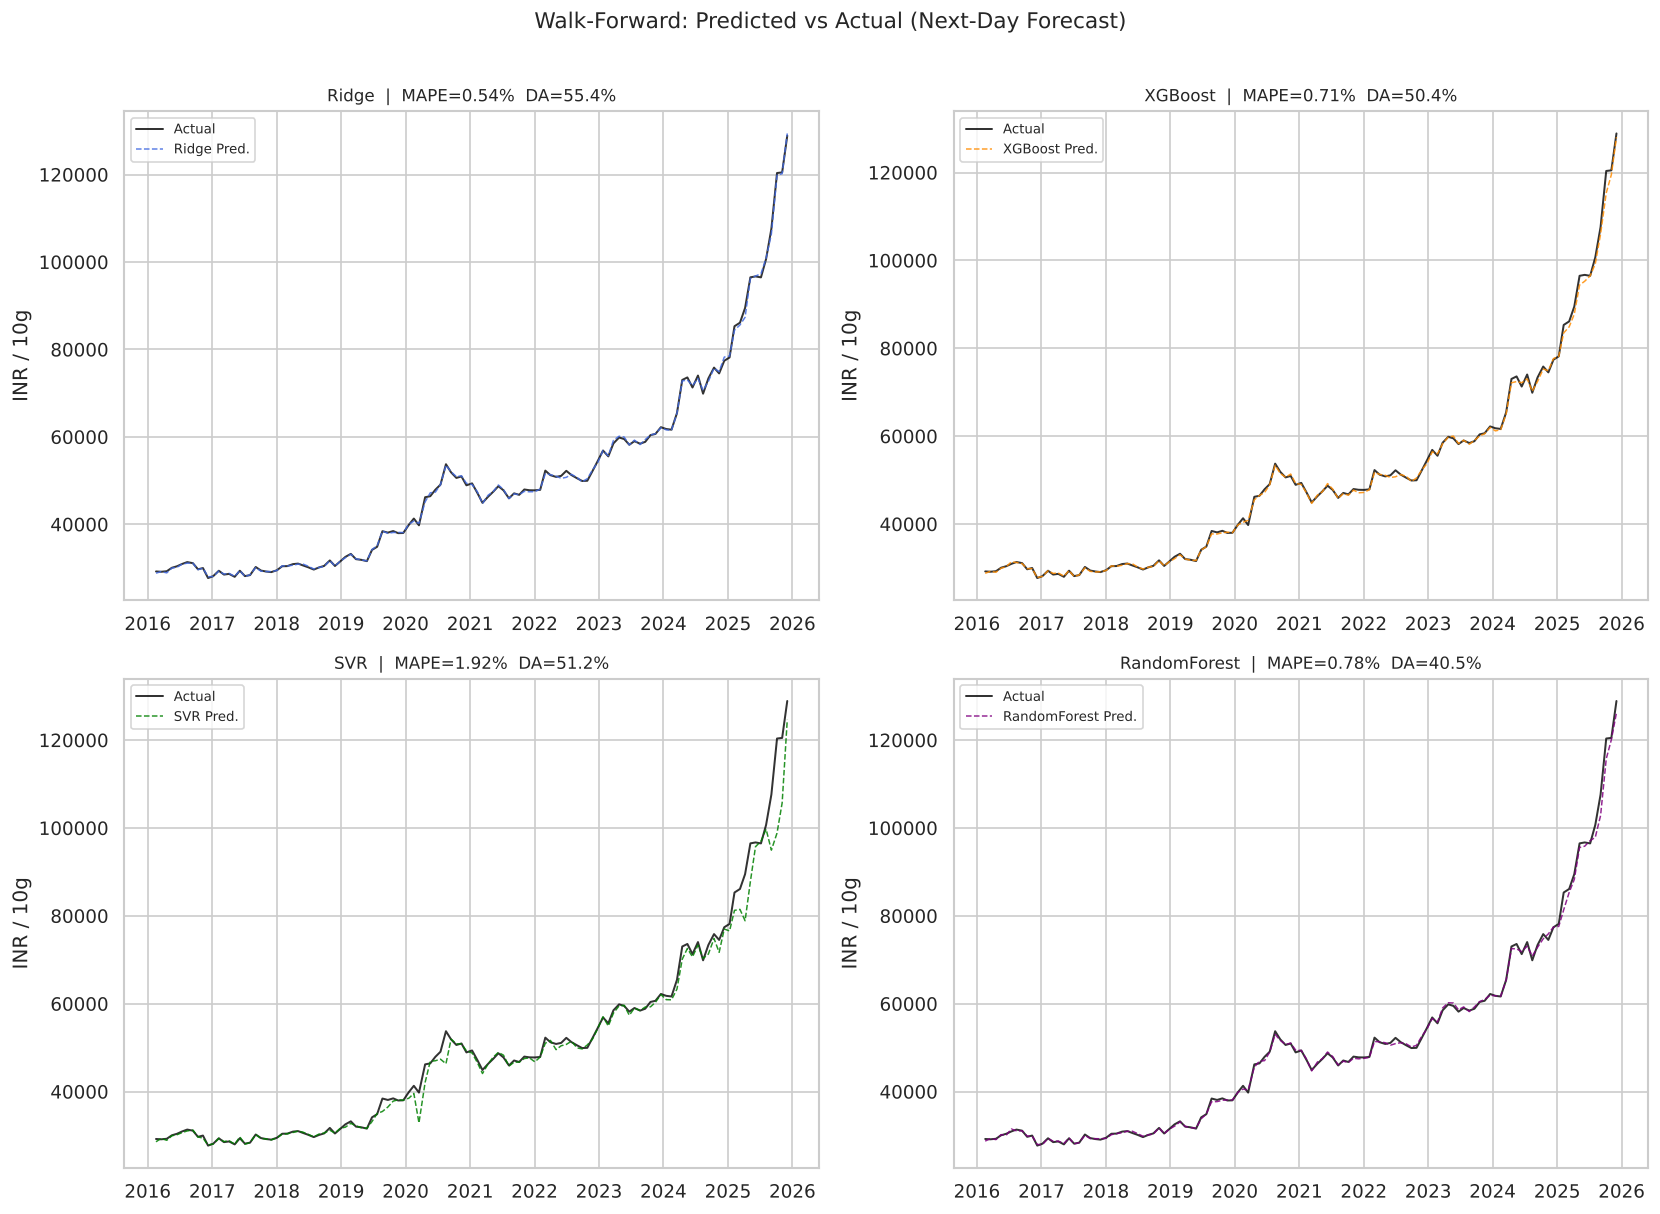

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

colors = {"Ridge": "royalblue", "XGBoost": "darkorange",
          "SVR": "green", "RandomForest": "purple"}

for ax, (name, folds) in zip(axes, [(m, wf_results[m]) for m in MODELS]):
    if not folds:
        ax.set_visible(False)
        continue
    dates  = [pd.Timestamp(f["date"]) for f in folds]
    actual = [f["y_true"] for f in folds]
    pred   = [f["y_pred"] for f in folds]

    ax.plot(dates, actual, lw=1.2, color="black", label="Actual", alpha=0.8)
    ax.plot(dates, pred,   lw=0.9, color=colors.get(name, "gray"),
            label=f"{name} Pred.", alpha=0.85, ls="--")
    ax.set_title(
        f"{name}  |  MAPE={summary[name]['mape_mean']:.2f}%  DA={summary[name]['da_pct']:.1f}%",
        fontsize=10
    )
    ax.set_ylabel("INR / 10g")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend(fontsize=8)

plt.suptitle("Walk-Forward: Predicted vs Actual (Next-Day Forecast)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("predicted_vs_actual.png", bbox_inches="tight")
plt.show()


## 8. Residual & Regime Analysis

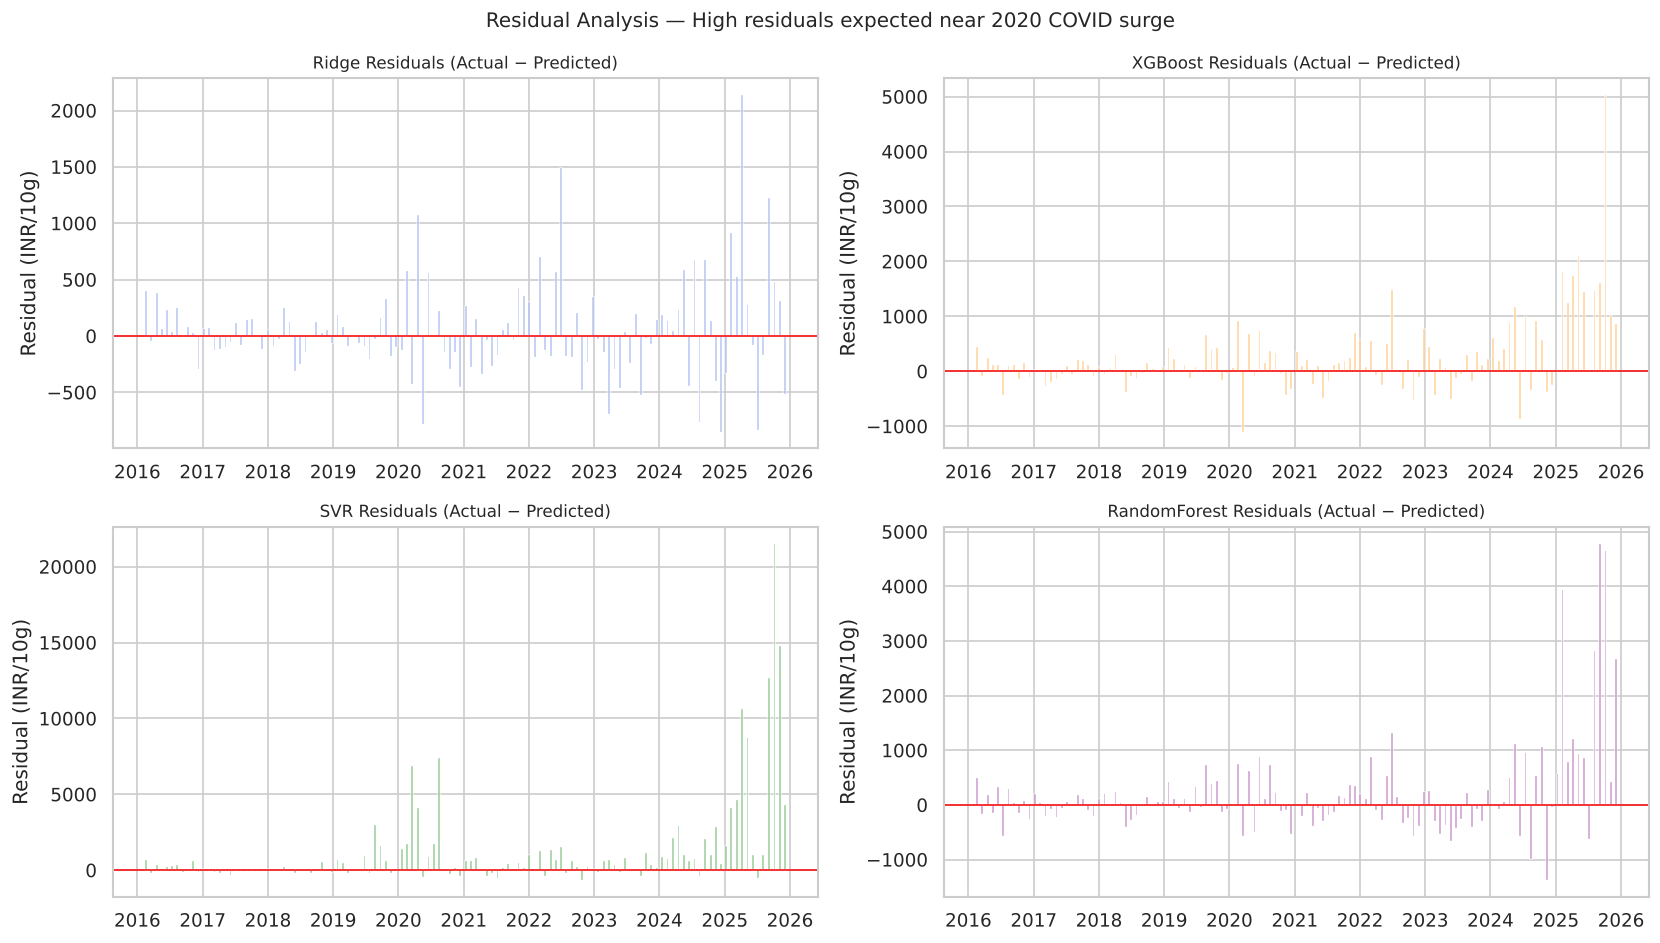

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, (name, folds) in zip(axes, [(m, wf_results[m]) for m in MODELS]):
    if not folds:
        ax.set_visible(False)
        continue
    dates     = [pd.Timestamp(f["date"]) for f in folds]
    residuals = [f["y_true"] - f["y_pred"] for f in folds]

    ax.bar(dates, residuals, width=10, color=colors.get(name, "gray"), alpha=0.6)
    ax.axhline(0, color="red", lw=0.9)
    ax.set_title(f"{name} Residuals (Actual − Predicted)", fontsize=10)
    ax.set_ylabel("Residual (INR/10g)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.suptitle("Residual Analysis — High residuals expected near 2020 COVID surge", fontsize=12)
plt.tight_layout()
plt.savefig("residual_analysis.png", bbox_inches="tight")
plt.show()


In [11]:
# ── Regime analysis: calm vs volatile ─────────────────────────
# Volatile period = 2020-01-01 to 2020-12-31 (COVID/gold surge)
print("=" * 60)
print("Performance by Regime: Calm vs COVID-Era Volatile (2020)")
print("=" * 60)

for name, folds in wf_results.items():
    if not folds:
        continue
    calm_mapes = [f["mape"] for f in folds if pd.Timestamp(f["date"]).year != 2020]
    vol_mapes  = [f["mape"] for f in folds if pd.Timestamp(f["date"]).year == 2020]
    calm_da    = [f["da"]   for f in folds if pd.Timestamp(f["date"]).year != 2020]
    vol_da     = [f["da"]   for f in folds if pd.Timestamp(f["date"]).year == 2020]

    c_mape = np.mean(calm_mapes) if calm_mapes else float("nan")
    v_mape = np.mean(vol_mapes)  if vol_mapes  else float("nan")
    c_da   = np.mean(calm_da)*100 if calm_da else float("nan")
    v_da   = np.mean(vol_da)*100  if vol_da  else float("nan")

    print(f"\n{name}:")
    print(f"  Calm periods   — MAPE: {c_mape:.2f}%  Dir.Acc: {c_da:.1f}%  (n={len(calm_mapes)})")
    print(f"  Volatile (2020)— MAPE: {v_mape:.2f}%  Dir.Acc: {v_da:.1f}%  (n={len(vol_mapes)})")


Performance by Regime: Calm vs COVID-Era Volatile (2020)

Ridge:
  Calm periods   — MAPE: 0.50%  Dir.Acc: 56.0%  (n=109)
  Volatile (2020)— MAPE: 0.87%  Dir.Acc: 50.0%  (n=12)

XGBoost:
  Calm periods   — MAPE: 0.68%  Dir.Acc: 51.4%  (n=109)
  Volatile (2020)— MAPE: 0.96%  Dir.Acc: 41.7%  (n=12)

SVR:
  Calm periods   — MAPE: 1.62%  Dir.Acc: 51.4%  (n=109)
  Volatile (2020)— MAPE: 4.63%  Dir.Acc: 50.0%  (n=12)

RandomForest:
  Calm periods   — MAPE: 0.77%  Dir.Acc: 41.3%  (n=109)
  Volatile (2020)— MAPE: 0.91%  Dir.Acc: 33.3%  (n=12)

Persistence:
  Calm periods   — MAPE: 0.50%  Dir.Acc: 0.0%  (n=109)
  Volatile (2020)— MAPE: 0.78%  Dir.Acc: 0.0%  (n=12)

7-day MA:
  Calm periods   — MAPE: 0.96%  Dir.Acc: 57.8%  (n=109)
  Volatile (2020)— MAPE: 1.03%  Dir.Acc: 50.0%  (n=12)


## 9. MAPE Distribution Across Folds

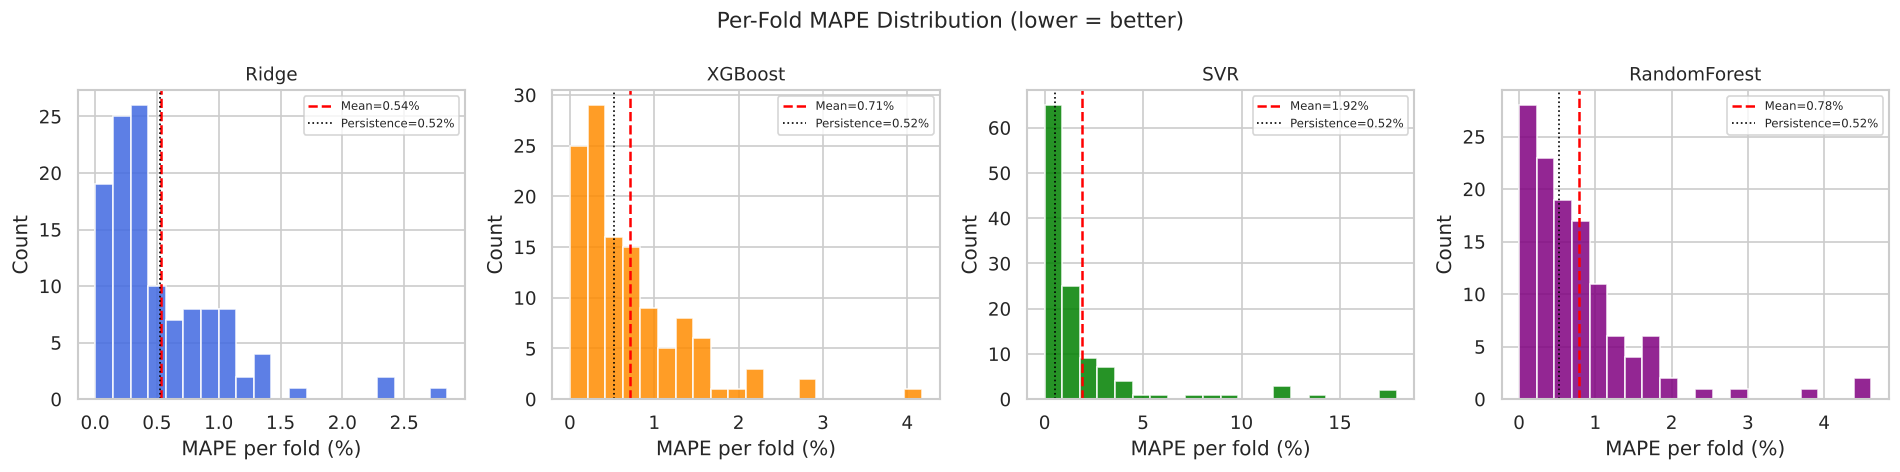

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (name, folds) in zip(axes, [(m, wf_results[m]) for m in MODELS]):
    if not folds:
        ax.set_visible(False)
        continue
    mapes = [f["mape"] for f in folds]
    ax.hist(mapes, bins=20, color=colors.get(name, "gray"), edgecolor="white", alpha=0.85)
    ax.axvline(np.mean(mapes), color="red",   lw=1.5, ls="--", label=f"Mean={np.mean(mapes):.2f}%")
    p_mape = summary["Persistence"]["mape_mean"]
    ax.axvline(p_mape,         color="black", lw=1.0, ls=":",  label=f"Persistence={p_mape:.2f}%")
    ax.set_title(f"{name}", fontsize=11)
    ax.set_xlabel("MAPE per fold (%)")
    ax.set_ylabel("Count")
    ax.legend(fontsize=7)

plt.suptitle("Per-Fold MAPE Distribution (lower = better)", fontsize=13)
plt.tight_layout()
plt.savefig("mape_distribution.png", bbox_inches="tight")
plt.show()


## 10. Conclusions

> **Corrected results.** An earlier version of this notebook had three evaluation bugs: (1) features were shifted one day too many, so the model never saw today's close; (2) "RMSE" was averaged over one-point folds, which is really MAE, and was compared against a persistence RMSE computed over all rows; (3) directional accuracy was measured against yesterday's close (`Lag_1`) instead of today's. All three are fixed above. Numbers below are from the corrected run (121 folds, identical test days for every model and baseline); re-running may shift tree-model figures slightly.

| Model | MAPE | RMSE (₹/10g, pooled) | Dir. Acc. |
|---|---|---|---|
| Ridge | 0.54% | 422 | 55.4% |
| XGBoost | 0.71% | 727 | 50.4% |
| Random Forest | 0.78% | 902 | 40.5% |
| SVR | 1.92% | 3,249 | 51.2% |
| Persistence (tomorrow = today) | 0.52% | 421 | 0% (predicts no change) |
| 7-day MA | 0.97% | 835 | 57.0% |

### Key Findings

1. **Persistence is the benchmark to beat, and nothing clearly beats it.** Ridge essentially matches it (0.54% vs 0.52% MAPE; 422 vs 421 RMSE) — Ridge has largely learned "tomorrow ≈ today".
2. **Tree models do worse than doing nothing.** Random Forest and XGBoost cannot extrapolate beyond the price range seen in training, which hurts in a series that trends to new highs.
3. **Directional accuracy is near a coin flip.** Ridge's 55.4% on 121 forecasts is not statistically distinguishable from 50%. The 7-day MA's 57.0% is a mean-reversion effect, not a forecasting edge.
4. **The 2020 regime claim does not hold.** On the 12 forecast days in 2020, Random Forest's directional accuracy was 33%, not the 75% reported before the fix.
5. **SVR remains the weakest model**, even with target scaling.

### Model Recommendation
Use persistence as the production baseline. Any model must beat it on pooled RMSE over the same test days before being considered useful.

### Limitations & Future Work
- Predict returns instead of price levels, so tree models are not limited by the training price range
- Add macro features: DXY, VIX, crude oil, US 10Y yield (see v2)
- Test multi-step forecasting (t+5, t+21)
- Report confidence intervals / Diebold–Mariano tests against persistence
